In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [44]:
df = pd.read_csv("../base/credit_risk_dataset.csv")

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [45]:
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

df.info()

Quantidade de linhas: 32581
Quantidade de colunas: 12
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage:

In [46]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [47]:
df.isnull().sum().sort_values(ascending=False)

loan_int_rate                 3116
person_emp_length              895
person_income                    0
person_age                       0
person_home_ownership            0
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [48]:
print(f"Total de registros duplicados: {df.duplicated().sum()}")

Total de registros duplicados: 165


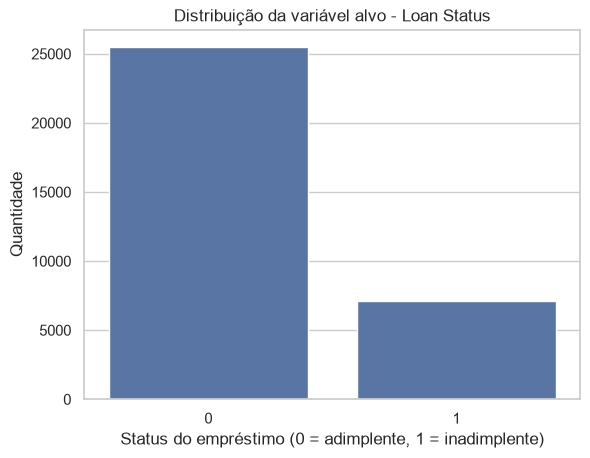

In [49]:
# Distribuição da variável alvo
sns.countplot(data=df, x="loan_status")

plt.title("Distribuição da variável alvo - Loan Status")
plt.xlabel("Status do empréstimo (0 = adimplente, 1 = inadimplente)")
plt.ylabel("Quantidade")
plt.show()

In [50]:
# Percentual de cada classe
df["loan_status"].value_counts(normalize=True) * 100

loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

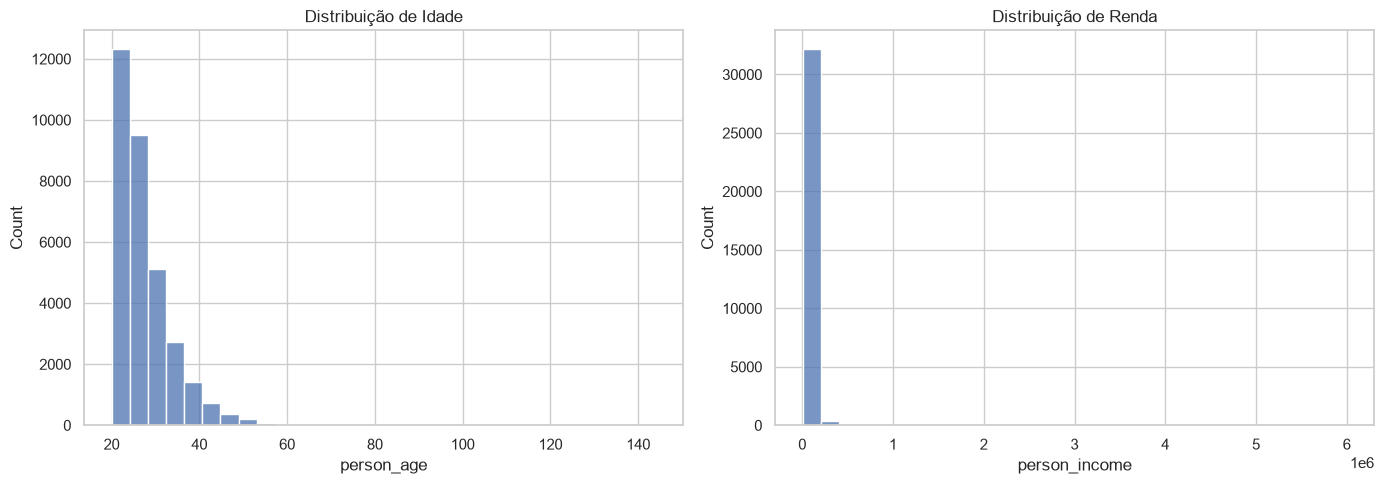

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["person_age"], bins=30, ax=axes[0])
axes[0].set_title("Distribuição de Idade")

sns.histplot(df["person_income"], bins=30, ax=axes[1])
axes[1].set_title("Distribuição de Renda")

plt.tight_layout()
plt.show()

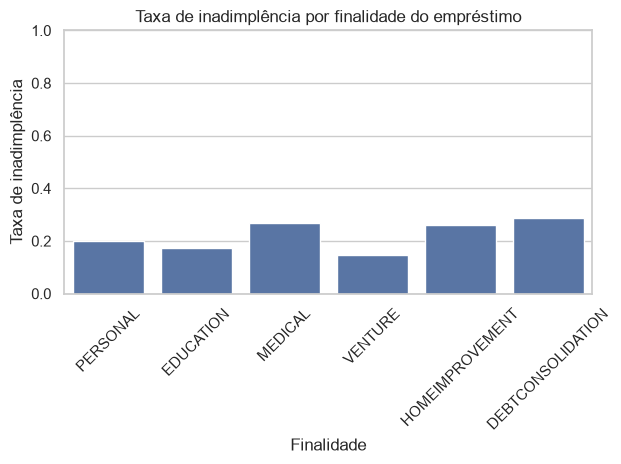

In [52]:
sns.barplot(
    data=df,
    x="loan_intent",
    y="loan_status",
    errorbar=None
)

plt.title("Taxa de inadimplência por finalidade do empréstimo")
plt.xlabel("Finalidade")
plt.ylabel("Taxa de inadimplência")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

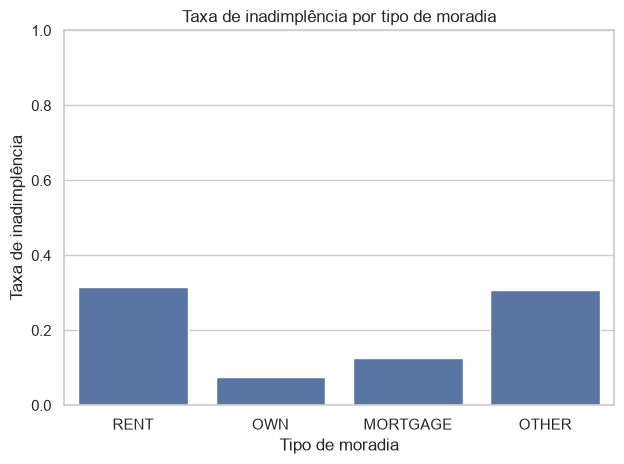

In [53]:
sns.barplot(
    data=df,
    x="person_home_ownership",
    y="loan_status",
    errorbar=None
)

plt.title("Taxa de inadimplência por tipo de moradia")
plt.xlabel("Tipo de moradia")
plt.ylabel("Taxa de inadimplência")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [54]:
colunas = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

df[colunas].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99, 0.995]
).T

,count,mean,std,min,1%,5%,50%,95%,99%,99.5%,max
person_age,32581.0,27.734600,6.348078,20.0,21.00,22.00,26.00,40.00,50.0,54.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.0,14400.00,22880.00,55000.00,138000.00,225200.0,300000.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.0,0.00,0.00,4.00,13.00,18.0,19.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.0,1000.00,2000.00,8000.00,24000.00,29800.0,35000.00,35000.00
loan_percent_income,32581.0,0.170203,0.106782,0.0,0.02,0.04,0.15,0.38,0.5,0.53,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.0,2.00,2.00,4.00,14.00,17.0,23.00,30.00


In [55]:
# Identificação de possíveis valores inconsistentes
df_outliers = df[
    (df["person_age"] > 100) |
    (df["person_emp_length"] > 60) |
    (df["person_income"] > 1_000_000)
]

df_outliers[
    ["person_age", "person_income", "person_emp_length",
     "loan_amnt", "loan_percent_income", "loan_status"]
]

,person_age,person_income,person_emp_length,loan_amnt,loan_percent_income,loan_status
0,22,59000,123.0,35000,0.59,1
81,144,250000,4.0,4800,0.02,0
183,144,200000,4.0,6000,0.03,0
210,21,192000,123.0,20000,0.10,0
575,123,80004,2.0,20400,0.25,0
747,123,78000,7.0,20000,0.26,0
17833,32,1200000,1.0,12000,0.01,0
29119,36,1200000,16.0,10000,0.01,0
29120,40,1200000,1.0,10000,0.01,0
30049,42,2039784,0.0,8450,0.00,0


In [56]:
# Quantidade de registros com cada inconsistência

print("Idades acima de 100:", (df["person_age"] > 100).sum())

print("Tempo de emprego acima de 60 anos:",
      (df["person_emp_length"] > 60).sum())

print("Renda acima de R$ 1 milhão:",
      (df["person_income"] > 1_000_000).sum())

print("Total de registros com algum desses problemas:",
      df_outliers.shape[0])

Idades acima de 100: 5
Tempo de emprego acima de 60 anos: 2
Renda acima de R$ 1 milhão: 9
Total de registros com algum desses problemas: 15


In [57]:
# Tratamento de valores claramente inválidos

df.loc[df["person_age"] > 100, "person_age"] = np.nan

df.loc[df["person_emp_length"] > 60, "person_emp_length"] = np.nan

print("Idades inválidas restantes:", (df["person_age"] > 100).sum())
print("Tempo de emprego inválido restante:", (df["person_emp_length"] > 60).sum())
print("Valores ausentes após tratamento:")
print(df[["person_age", "person_emp_length"]].isnull().sum())

Idades inválidas restantes: 0
Tempo de emprego inválido restante: 0
Valores ausentes após tratamento:
person_age             5
person_emp_length    897
dtype: int64


In [58]:
# Investigação de registros duplicados

print("Total de registros duplicados:", df.duplicated().sum())

df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
).head(10)

Total de registros duplicados: 165


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21.0,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21.0,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21.0,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21.0,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21.0,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21.0,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21.0,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21.0,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21.0,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21.0,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


In [59]:
# Remoção de registros duplicados
duplicados_antes = df.duplicated().sum()

df = df.drop_duplicates().copy()

duplicados_depois = df.duplicated().sum()

print("Duplicados removidos:", duplicados_antes)
print("Duplicados restantes:", duplicados_depois)
print("Dimensão final da base:", df.shape)

Duplicados removidos: 165
Duplicados restantes: 0
Dimensão final da base: (32416, 12)


In [60]:
# Análise de valores ausentes após limpeza

missing = pd.DataFrame({
    "Valores ausentes": df.isnull().sum(),
    "Percentual (%)": (df.isnull().mean() * 100).round(2)
})

missing = missing[missing["Valores ausentes"] > 0].sort_values(
    "Percentual (%)", ascending=False
)

missing

,Valores ausentes,Percentual (%)
loan_int_rate,3095,9.55
person_emp_length,889,2.74
person_age,5,0.02


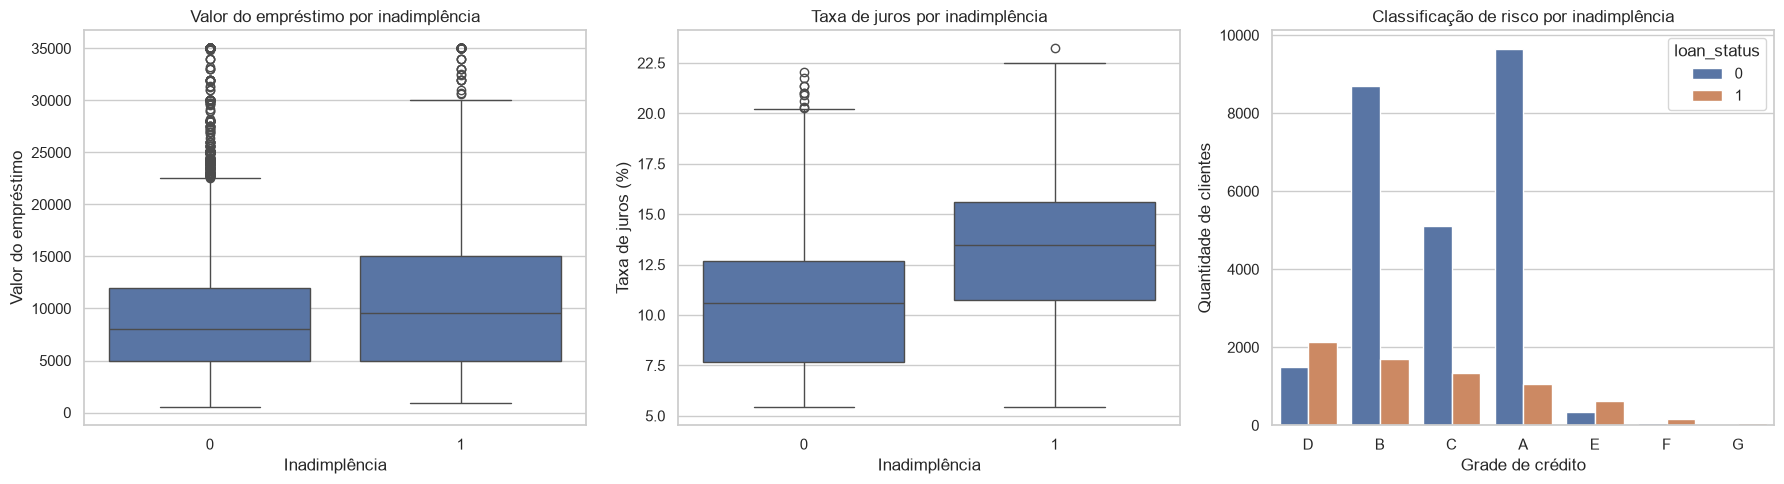

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="loan_status", y="loan_amnt", ax=axes[0])
axes[0].set_title("Valor do empréstimo por inadimplência")
axes[0].set_xlabel("Inadimplência")
axes[0].set_ylabel("Valor do empréstimo")

sns.boxplot(data=df, x="loan_status", y="loan_int_rate", ax=axes[1])
axes[1].set_title("Taxa de juros por inadimplência")
axes[1].set_xlabel("Inadimplência")
axes[1].set_ylabel("Taxa de juros (%)")

sns.countplot(data=df, x="loan_grade", hue="loan_status", ax=axes[2])
axes[2].set_title("Classificação de risco por inadimplência")
axes[2].set_xlabel("Grade de crédito")
axes[2].set_ylabel("Quantidade de clientes")

plt.tight_layout()
plt.show()

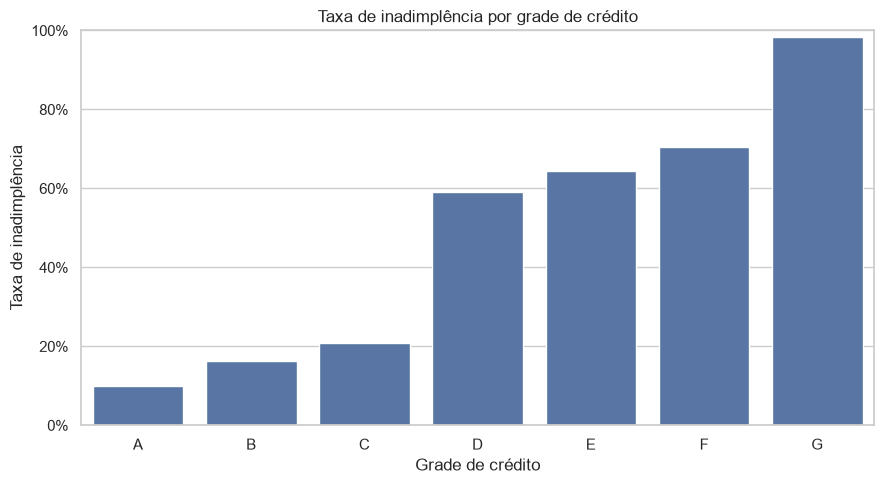

In [62]:
# Taxa de inadimplência por grade de crédito
inadimplencia_grade = df.groupby("loan_grade")["loan_status"].mean().sort_index()

plt.figure(figsize=(9, 5))
sns.barplot(x=inadimplencia_grade.index, y=inadimplencia_grade.values)

plt.title("Taxa de inadimplência por grade de crédito")
plt.xlabel("Grade de crédito")
plt.ylabel("Taxa de inadimplência")
plt.ylim(0, 1)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

plt.tight_layout()
plt.show()

In [63]:
# Consolidar quantidade de clientes e taxa de inadimplência por grade
resumo_grade = df.groupby("loan_grade")["loan_status"].agg(
    quantidade="count",
    inadimplencia="mean"
)

resumo_grade["inadimplencia"] = (
    resumo_grade["inadimplencia"] * 100
).round(2)

resumo_grade

,quantidade,inadimplencia
loan_grade,,
A,10703,9.96
B,10387,16.32
C,6438,20.75
D,3620,59.06
E,963,64.49
F,241,70.54
G,64,98.44


## Principais achados da análise exploratória

- A base original contém 32.581 registros e 12 variáveis.
- Foram identificados 165 registros duplicados, removidos durante a limpeza.
- Foram encontrados valores inconsistentes nas variáveis `person_age` e `person_emp_length`, tratados como valores ausentes.
- A variável `loan_int_rate` possui aproximadamente 9,55% de valores ausentes, enquanto `person_emp_length` possui 2,74% e `person_age` 0,02% após a limpeza.
- A distribuição da variável alvo apresenta predominância de clientes adimplentes, indicando desbalanceamento entre as classes.
- Clientes inadimplentes apresentam, visualmente, valores de empréstimo e taxas de juros mais elevados.
- A variável `loan_grade` apresenta forte associação com a inadimplência, com aumento expressivo das taxas nas grades de maior risco. A grade G apresentou 98,44% de inadimplência, porém possui apenas 64 registros.
- Os valores extremos de renda foram mantidos, pois não representam necessariamente erros de dados.

### Conclusão

A análise exploratória identificou padrões relevantes associados à inadimplência, além de inconsistências e valores ausentes que exigem tratamento. Os resultados orientam as próximas etapas de preparação dos dados, engenharia de atributos e construção dos modelos de classificação.

In [64]:
from pathlib import Path
import sys

# Adiciona a raiz do projeto ao caminho de importação
raiz_projeto = Path("..").resolve()
sys.path.append(str(raiz_projeto))

from src.features import criar_features

# Teste com a base atual
df_teste = criar_features(df)

print("Feature criada:", "comprometimento_renda" in df_teste.columns)
print("Dataframe original preservado:", "comprometimento_renda" not in df.columns)
print("Valores ausentes na nova feature:", df_teste["comprometimento_renda"].isnull().sum())

df_teste[[
    "loan_amnt",
    "person_income",
    "loan_percent_income",
    "comprometimento_renda"
]].head(10)

Feature criada: True
Dataframe original preservado: True
Valores ausentes na nova feature: 0


,loan_amnt,person_income,loan_percent_income,comprometimento_renda
0,35000,59000,0.59,59.322034
1,1000,9600,0.10,10.416667
2,5500,9600,0.57,57.291667
3,35000,65500,0.53,53.435115
4,35000,54400,0.55,64.338235
5,2500,9900,0.25,25.252525
6,35000,77100,0.45,45.395590
7,35000,78956,0.44,44.328487
8,35000,83000,0.42,42.168675
9,1600,10000,0.16,16.000000


In [65]:
from pathlib import Path
import sys
import importlib

# Adiciona a raiz do projeto ao caminho de importação
raiz_projeto = Path("..").resolve()

if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

# Importa e recarrega o módulo
import src.features as features
importlib.reload(features)

criar_features = features.criar_features

# Teste com a base atual
df_teste = criar_features(df)

print("Feature criada:", "comprometimento_renda" in df_teste.columns)
print("Dataframe original preservado:", "comprometimento_renda" not in df.columns)
print("Valores ausentes na nova feature:", df_teste["comprometimento_renda"].isnull().sum())

df_teste[[
    "loan_amnt",
    "person_income",
    "loan_percent_income",
    "comprometimento_renda"
]].head(10)

Feature criada: True
Dataframe original preservado: True
Valores ausentes na nova feature: 0


,loan_amnt,person_income,loan_percent_income,comprometimento_renda
0,35000,59000,0.59,59.322034
1,1000,9600,0.10,10.416667
2,5500,9600,0.57,57.291667
3,35000,65500,0.53,53.435115
4,35000,54400,0.55,64.338235
5,2500,9900,0.25,25.252525
6,35000,77100,0.45,45.395590
7,35000,78956,0.44,44.328487
8,35000,83000,0.42,42.168675
9,1600,10000,0.16,16.000000


In [66]:
# Verificar colunas e tipos de dados
df.dtypes

person_age                    float64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [67]:
# Separar variáveis numéricas e categóricas
variaveis_numericas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
variaveis_categoricas = df.select_dtypes(include=["object"]).columns.tolist()

print("Variáveis numéricas:")
print(variaveis_numericas)

print("\nVariáveis categóricas:")
print(variaveis_categoricas)

Variáveis numéricas:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_cred_hist_length']

Variáveis categóricas:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


C:\Users\Stefano\AppData\Local\Temp\ipykernel_12572\3650166359.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variaveis_categoricas = df.select_dtypes(include=["object"]).columns.tolist()


In [68]:
# Definição da variável alvo
target = "loan_status"

# Variáveis numéricas
variaveis_numericas = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "cb_person_cred_hist_length",
    "comprometimento_renda"
]

# Variáveis categóricas
variaveis_categoricas = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]

# Consolidar as variáveis preditoras
features = variaveis_numericas + variaveis_categoricas

print("Target:", target)
print("\nTotal de preditoras:", len(features))
print("\nNuméricas:", len(variaveis_numericas))
print("Categóricas:", len(variaveis_categoricas))
print("\nFeatures selecionadas:")
print(features)

Target: loan_status

Total de preditoras: 10

Numéricas: 7
Categóricas: 3

Features selecionadas:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'cb_person_cred_hist_length', 'comprometimento_renda', 'person_home_ownership', 'loan_intent', 'cb_person_default_on_file']


In [69]:
from sklearn.model_selection import train_test_split

# Aplicar a engenharia de atributos na base
df_modelagem = criar_features(df)

# Separar preditoras e variável alvo
X = df_modelagem[features]
y = df_modelagem[target]

# Separação estratificada: 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensões:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDistribuição da variável alvo:")
print("Treino:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTeste:")
print(y_test.value_counts(normalize=True).sort_index())

Dimensões:
X_train: (25932, 10)
X_test: (6484, 10)
y_train: (25932,)
y_test: (6484,)

Distribuição da variável alvo:
Treino:
loan_status
0    0.781313
1    0.218687
Name: proportion, dtype: float64

Teste:
loan_status
0    0.781308
1    0.218692
Name: proportion, dtype: float64


In [70]:
from pathlib import Path
import sys
import importlib

# Garantir que a raiz do projeto esteja no caminho
raiz_projeto = Path("..").resolve()

if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

# Importar e recarregar o pré-processador
import src.preprocessing as preprocessing
importlib.reload(preprocessing)

# Criar o pré-processador
preprocessador = preprocessing.criar_preprocessador()

# Ajustar somente com os dados de treino
X_train_processado = preprocessador.fit_transform(X_train)

# Transformar os dados de teste sem reajustar
X_test_processado = preprocessador.transform(X_test)

# Validar resultados
print("Dimensões originais:")
print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDimensões após pré-processamento:")
print("Treino:", X_train_processado.shape)
print("Teste:", X_test_processado.shape)

print("\nTipo de saída:")
print(type(X_train_processado))

Dimensões originais:
Treino: (25932, 10)
Teste: (6484, 10)

Dimensões após pré-processamento:
Treino: (25932, 19)
Teste: (6484, 19)

Tipo de saída:
<class 'numpy.ndarray'>


In [71]:
import numpy as np

print("Valores NaN no treino:", np.isnan(X_train_processado).sum())
print("Valores NaN no teste:", np.isnan(X_test_processado).sum())

print("Valores infinitos no treino:", np.isinf(X_train_processado).sum())
print("Valores infinitos no teste:", np.isinf(X_test_processado).sum())

print("Quantidade de colunas igual:", 
      X_train_processado.shape[1] == X_test_processado.shape[1])

Valores NaN no treino: 0
Valores NaN no teste: 0
Valores infinitos no treino: 0
Valores infinitos no teste: 0
Quantidade de colunas igual: True


In [72]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

from model_training import criar_pipeline_modelo, criar_modelos

print("Módulo de treinamento importado com sucesso!")
print(criar_modelos())

Módulo de treinamento importado com sucesso!
{'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42), 'RandomForest': RandomForestClassifier(n_jobs=-1, random_state=42)}


In [73]:
modelos = criar_modelos()

pipelines = {}

for nome, modelo in modelos.items():
    pipelines[f"{nome}_baseline"] = criar_pipeline_modelo(
        modelo=modelo,
        balancear=False
    )

    pipelines[f"{nome}_balanceado"] = criar_pipeline_modelo(
        modelo=modelo,
        balancear=True
    )

for nome, pipeline in pipelines.items():
    print(f"\n{nome}")
    print(pipeline.steps)


LogisticRegression_baseline
[('preprocessador', ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalonador',
                                                  StandardScaler())]),
                                 ['person_age', 'person_income',
                                  'person_emp_length', 'loan_amnt',
                                  'loan_int_rate', 'cb_person_cred_hist_length',
                                  'comprometimento_renda']),
                                ('categoricas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('codificador',
                                                  OneHotEncoder(handle_unknown

In [74]:
modelos = criar_modelos()

pipelines = {}

for nome, modelo in modelos.items():
    pipelines[f"{nome}_baseline"] = criar_pipeline_modelo(
        modelo=modelo,
        balancear=False
    )

    pipelines[f"{nome}_balanceado"] = criar_pipeline_modelo(
        modelo=modelo,
        balancear=True
    )

for nome, pipeline in pipelines.items():
    print(f"{nome}: {[etapa for etapa, _ in pipeline.steps]}")

LogisticRegression_baseline: ['preprocessador', 'modelo']
LogisticRegression_balanceado: ['preprocessador', 'balanceador', 'modelo']
RandomForest_baseline: ['preprocessador', 'modelo']
RandomForest_balanceado: ['preprocessador', 'balanceador', 'modelo']


In [75]:
import importlib
import model_training

importlib.reload(model_training)

criar_pipeline_modelo = model_training.criar_pipeline_modelo
criar_modelos = model_training.criar_modelos

In [76]:
modelos = criar_modelos()

pipelines = {}

for nome, modelo in modelos.items():
    pipelines[f"{nome}_baseline"] = criar_pipeline_modelo(
        modelo=modelo,
        balancear=False
    )

    pipelines[f"{nome}_balanceado"] = criar_pipeline_modelo(
        modelo=modelo,
        balancear=True
    )

for nome, pipeline in pipelines.items():
    print(f"{nome}: {[etapa for etapa, _ in pipeline.steps]}")

LogisticRegression_baseline: ['preprocessador', 'modelo']
LogisticRegression_balanceado: ['preprocessador', 'balanceador', 'modelo']
RandomForest_baseline: ['preprocessador', 'modelo']
RandomForest_balanceado: ['preprocessador', 'balanceador', 'modelo']


In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

resultados = []

for nome, pipeline in pipelines.items():

    print(f"Treinando {nome}...")

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    resultados.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

    print("Matriz de confusão:")
    print(confusion_matrix(y_test, y_pred))
    print("-" * 50)

Treinando LogisticRegression_baseline...
Matriz de confusão:
[[4842  224]
 [ 742  676]]
--------------------------------------------------
Treinando LogisticRegression_balanceado...
Matriz de confusão:
[[3963 1103]
 [ 328 1090]]
--------------------------------------------------
Treinando RandomForest_baseline...
Matriz de confusão:
[[5010   56]
 [ 452  966]]
--------------------------------------------------
Treinando RandomForest_balanceado...
Matriz de confusão:
[[4960  106]
 [ 420  998]]
--------------------------------------------------


In [78]:
df_resultados = pd.DataFrame(resultados)

df_resultados.sort_values(
    by="F1",
    ascending=False
).round(4)

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
2,RandomForest_baseline,0.9217,0.9452,0.6812,0.7918,0.9219
3,RandomForest_balanceado,0.9189,0.9040,0.7038,0.7914,0.9225
1,LogisticRegression_balanceado,0.7793,0.4970,0.7687,0.6037,0.8549
0,LogisticRegression_baseline,0.8510,0.7511,0.4767,0.5833,0.8544


In [79]:
for nome, pipeline in pipelines.items():
    if "balanceador" in pipeline.named_steps:
        print(nome, pipeline.named_steps["balanceador"])

LogisticRegression_balanceado RandomOverSampler(random_state=42)
RandomForest_balanceado RandomOverSampler(random_state=42)


## 4. Treinamento e otimização de modelos

In [80]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Configuração dos experimentos
experimentos = {
    "LogisticRegression_baseline": {
        "pipeline": criar_pipeline_modelo(
            LogisticRegression(max_iter=1000, random_state=42),
            balancear=False
        ),
        "parametros": {
            "modelo__C": [0.01, 0.1, 1, 10]
        }
    },

    "LogisticRegression_balanceado": {
        "pipeline": criar_pipeline_modelo(
            LogisticRegression(max_iter=1000, random_state=42),
            balancear=True
        ),
        "parametros": {
            "modelo__C": [0.01, 0.1, 1, 10]
        }
    },

    "RandomForest_baseline": {
        "pipeline": criar_pipeline_modelo(
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            ),
            balancear=False
        ),
        "parametros": {
            "modelo__max_depth": [5, 10, 15, None]
        }
    },

    "RandomForest_balanceado": {
        "pipeline": criar_pipeline_modelo(
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            ),
            balancear=True
        ),
        "parametros": {
            "modelo__max_depth": [5, 10, 15, None]
        }
    }
}

resultados_cv = []
modelos_treinados = {}

for nome, experimento in experimentos.items():

    print(f"\nOtimizando: {nome}")

    busca = GridSearchCV(
        estimator=experimento["pipeline"],
        param_grid=experimento["parametros"],
        scoring="f1",
        cv=cv,
        n_jobs=1,
        return_train_score=True,
        verbose=1
    )

    busca.fit(X_train, y_train)

    modelos_treinados[nome] = busca

    resultados_cv.append({
        "Modelo": nome,
        "Melhor parâmetro": busca.best_params_,
        "F1 CV": busca.best_score_,
        "F1 Treino": busca.cv_results_["mean_train_score"][
            busca.best_index_
        ],
        "Diferença Treino-CV": (
            busca.cv_results_["mean_train_score"][busca.best_index_]
            - busca.best_score_
        )
    })

    print("Melhores parâmetros:", busca.best_params_)
    print(f"Melhor F1 CV: {busca.best_score_:.4f}")

df_resultados_cv = pd.DataFrame(resultados_cv)

df_resultados_cv.sort_values(
    by="F1 CV",
    ascending=False
).reset_index(drop=True)


Otimizando: LogisticRegression_baseline
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhores parâmetros: {'modelo__C': 10}
Melhor F1 CV: 0.5732

Otimizando: LogisticRegression_balanceado
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhores parâmetros: {'modelo__C': 10}
Melhor F1 CV: 0.5993

Otimizando: RandomForest_baseline
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhores parâmetros: {'modelo__max_depth': None}
Melhor F1 CV: 0.7778

Otimizando: RandomForest_balanceado
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhores parâmetros: {'modelo__max_depth': None}
Melhor F1 CV: 0.7804


,Modelo,Melhor parâmetro,F1 CV,F1 Treino,Diferença Treino-CV
0,RandomForest_balanceado,{'modelo__max_depth': None},0.780367,1.000000,0.219633
1,RandomForest_baseline,{'modelo__max_depth': None},0.777811,0.999912,0.222101
2,LogisticRegression_balanceado,{'modelo__C': 10},0.599332,0.600234,0.000902
3,LogisticRegression_baseline,{'modelo__C': 10},0.573225,0.575825,0.002600


In [81]:
resultados_rf = []

for nome in ["RandomForest_baseline", "RandomForest_balanceado"]:

    busca = modelos_treinados[nome]

    for i, params in enumerate(busca.cv_results_["params"]):

        resultados_rf.append({
            "Modelo": nome,
            "Max Depth": params["modelo__max_depth"],
            "F1 Treino": busca.cv_results_["mean_train_score"][i],
            "F1 CV": busca.cv_results_["mean_test_score"][i],
            "Gap": (
                busca.cv_results_["mean_train_score"][i]
                - busca.cv_results_["mean_test_score"][i]
            )
        })

df_rf_complexidade = pd.DataFrame(resultados_rf)

df_rf_complexidade.sort_values(
    ["Modelo", "F1 CV"],
    ascending=[True, False]
).reset_index(drop=True)

,Modelo,Max Depth,F1 Treino,F1 CV,Gap
0,RandomForest_balanceado,NaN,1.000000,0.780367,0.219633
1,RandomForest_balanceado,15.0,0.958919,0.774727,0.184192
2,RandomForest_balanceado,10.0,0.834318,0.754557,0.079760
3,RandomForest_balanceado,5.0,0.713195,0.705399,0.007796
4,RandomForest_baseline,NaN,0.999912,0.777811,0.222101
5,RandomForest_baseline,15.0,0.889953,0.774576,0.115378
6,RandomForest_baseline,10.0,0.806669,0.764490,0.042179
7,RandomForest_baseline,5.0,0.674112,0.665423,0.008689


In [82]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

pipeline_rf = criar_pipeline_modelo(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    balancear=False
)

parametros_rf = {
    "modelo__max_depth": [10, 15],
    "modelo__min_samples_leaf": [2, 5, 10],
    "modelo__class_weight": [None, "balanced"]
}

busca_rf_refinada = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=parametros_rf,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    verbose=1
)

busca_rf_refinada.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__class_weight': [None, 'balanced'], 'modelo__max_depth': [10, 15], 'modelo__min_samples_leaf': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_par

In [83]:
df_refinamento_rf = pd.DataFrame(
    busca_rf_refinada.cv_results_
)

df_refinamento_rf = df_refinamento_rf[
    [
        "param_modelo__max_depth",
        "param_modelo__min_samples_leaf",
        "param_modelo__class_weight",
        "mean_train_score",
        "mean_test_score"
    ]
].copy()

df_refinamento_rf["Gap"] = (
    df_refinamento_rf["mean_train_score"]
    - df_refinamento_rf["mean_test_score"]
)

df_refinamento_rf = df_refinamento_rf.sort_values(
    "mean_test_score",
    ascending=False
).reset_index(drop=True)

df_refinamento_rf

,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__class_weight,mean_train_score,mean_test_score,Gap
0,15,2,NaN,0.857639,0.772759,0.084880
1,15,5,NaN,0.812897,0.768753,0.044144
2,10,2,NaN,0.800867,0.768380,0.032487
3,15,2,balanced,0.925238,0.767582,0.157656
4,15,10,NaN,0.789672,0.765528,0.024144
5,10,5,NaN,0.790729,0.763292,0.027438
6,10,10,NaN,0.780325,0.761610,0.018716
7,15,5,balanced,0.869289,0.757531,0.111757
8,10,2,balanced,0.815346,0.745437,0.069909
9,15,10,balanced,0.816917,0.744228,0.072689


In [84]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Definição do modelo final candidato
modelo_final = criar_pipeline_modelo(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        min_samples_split=2,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ),
    balancear=False
)

# Treinamento
modelo_final.fit(X_train, y_train)

# Predições
y_pred_final = modelo_final.predict(X_test)
y_prob_final = modelo_final.predict_proba(X_test)[:, 1]

# Métricas
metricas_final = {
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "Recall": recall_score(y_test, y_pred_final),
    "F1": f1_score(y_test, y_pred_final),
    "ROC-AUC": roc_auc_score(y_test, y_prob_final)
}

pd.DataFrame(
    [metricas_final],
    index=["Random Forest Final"
]).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest Final,0.9204,0.9537,0.6685,0.7861,0.9186


In [85]:
# Matriz de confusão
cm = confusion_matrix(y_test, y_pred_final)

print("Matriz de confusão:")
print(cm)

print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Adimplente", "Inadimplente"]
))

Matriz de confusão:
[[5020   46]
 [ 470  948]]

Relatório de classificação:
              precision    recall  f1-score   support

  Adimplente       0.91      0.99      0.95      5066
Inadimplente       0.95      0.67      0.79      1418

    accuracy                           0.92      6484
   macro avg       0.93      0.83      0.87      6484
weighted avg       0.92      0.92      0.92      6484



In [86]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Probabilidades out-of-fold no conjunto de treino
probabilidades_oof = cross_val_predict(
    modelo_final,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Thresholds para comparação
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]

resultados_threshold = []

for threshold in thresholds:

    predicoes = (probabilidades_oof >= threshold).astype(int)

    resultados_threshold.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predicoes),
        "Recall": recall_score(y_train, predicoes),
        "F1": f1_score(y_train, predicoes)
    })

df_threshold = pd.DataFrame(resultados_threshold)

df_threshold.round(4)

,Threshold,Precision,Recall,F1
0,0.20,0.6328,0.8034,0.7079
1,0.25,0.7221,0.7644,0.7427
2,0.30,0.7977,0.7316,0.7632
3,0.35,0.8510,0.7092,0.7737
4,0.40,0.8892,0.6905,0.7774
5,0.45,0.9165,0.6720,0.7755
6,0.50,0.9330,0.6537,0.7688
7,0.55,0.9510,0.6406,0.7656


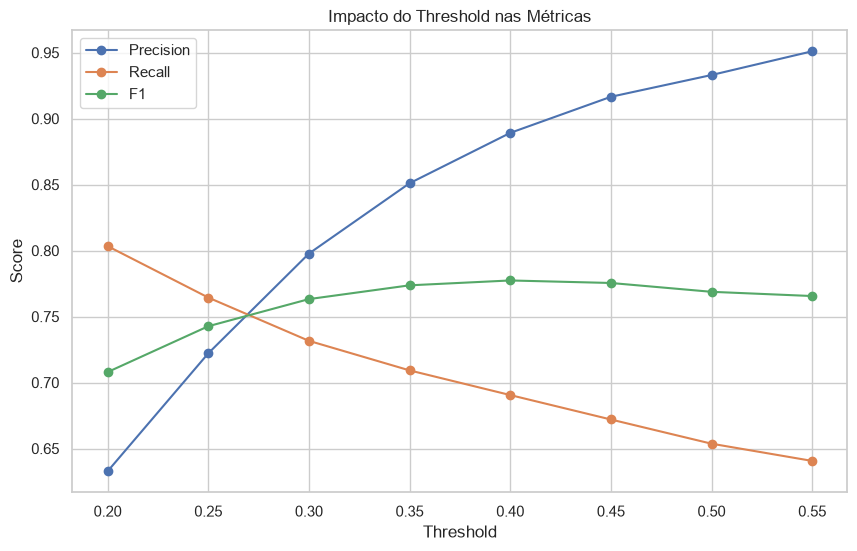

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    df_threshold["Threshold"],
    df_threshold["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    df_threshold["Threshold"],
    df_threshold["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    df_threshold["Threshold"],
    df_threshold["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Impacto do Threshold nas Métricas")
plt.legend()
plt.grid(True)
plt.show()

In [88]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score
)
import pandas as pd

threshold_final = 0.40

# Predições com threshold ajustado
y_pred_040 = (y_prob_final >= threshold_final).astype(int)

# Predições com threshold padrão
y_pred_050 = (y_prob_final >= 0.50).astype(int)

comparacao_thresholds = []

for threshold, pred in [
    (0.50, y_pred_050),
    (0.40, y_pred_040)
]:
    comparacao_thresholds.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob_final)
    })

df_comparacao_thresholds = pd.DataFrame(
    comparacao_thresholds
)

df_comparacao_thresholds.round(4)

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.5,0.9204,0.9537,0.6685,0.7861,0.9186
1,0.4,0.9186,0.9167,0.6904,0.7876,0.9186


In [89]:
cm_040 = confusion_matrix(y_test, y_pred_040)

print("Matriz de confusão - Threshold 0.40")
print(cm_040)

print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred_040,
    target_names=["Adimplente", "Inadimplente"]
))

Matriz de confusão - Threshold 0.40
[[4977   89]
 [ 439  979]]

Relatório de classificação:
              precision    recall  f1-score   support

  Adimplente       0.92      0.98      0.95      5066
Inadimplente       0.92      0.69      0.79      1418

    accuracy                           0.92      6484
   macro avg       0.92      0.84      0.87      6484
weighted avg       0.92      0.92      0.91      6484



In [91]:
import joblib
from pathlib import Path
from datetime import datetime

# Identificar raiz do projeto
raiz_projeto = Path.cwd()

if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

# Criar diretório models
diretorio_modelos = raiz_projeto / "models"
diretorio_modelos.mkdir(exist_ok=True)

# Métricas no threshold 0.50
metricas_050 = {
    "accuracy": accuracy_score(y_test, y_pred_050),
    "precision": precision_score(y_test, y_pred_050),
    "recall": recall_score(y_test, y_pred_050),
    "f1": f1_score(y_test, y_pred_050),
    "roc_auc": roc_auc_score(y_test, y_prob_final)
}

# Métricas no threshold 0.40
metricas_040 = {
    "accuracy": accuracy_score(y_test, y_pred_040),
    "precision": precision_score(y_test, y_pred_040),
    "recall": recall_score(y_test, y_pred_040),
    "f1": f1_score(y_test, y_pred_040),
    "roc_auc": roc_auc_score(y_test, y_prob_final)
}

# Artefato completo
artefato_modelo = {
    "model": modelo_final,
    "threshold": 0.40,
    "metadata": {
        "model_name": "RandomForestClassifier",
        "max_depth": 15,
        "min_samples_leaf": 5,
        "min_samples_split": 2,
        "n_estimators": 100,
        "class_weight": None,
        "balanceamento": False,
        "threshold_selection": "F1 maximizado na validação OOF",
        "f1_cv": 0.768753,
        "test_metrics_threshold_050": metricas_050,
        "test_metrics_threshold_040": metricas_040,
        "created_at": datetime.now().isoformat(),
        "random_state": 42
    }
}

# Salvar
caminho_modelo = diretorio_modelos / "modelo_risco_credito.joblib"

joblib.dump(artefato_modelo, caminho_modelo)

print("Modelo salvo com sucesso!")
print(f"Arquivo: {caminho_modelo}")
print(f"Tamanho: {caminho_modelo.stat().st_size / 1024:.2f} KB")

Modelo salvo com sucesso!
Arquivo: c:\Users\Stefano\Desktop\PROJETO_SCTEC_3_STEFANO_LAURITO\models\modelo_risco_credito.joblib
Tamanho: 12470.12 KB
